# IoU Threshold Plot

In [79]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [80]:
datasets_color = {'BBBC039':'#FFC0CB',
                   'mnfinder_test':'#80ED99',
                   'mnDINO_data_01':'#192A56',
                   'mnDINO_data_02':'#00A3FF'}

methods_color = {'mnDINO':'#00B4D8',
                  'MNFinder':'#4F00BC',
                  'MicroNucML':'#9900ffff',
                  'UNet':'#e22f80ff',
                  'CP-SAM':'#D90429',
                  'Cellpose3':'#ff8f00ff',
                  'microSAM':'#FFC300'}

objects_color = {'Nuc':'#00A3FF',
                 'MN':'#A68CFF'}


# Add a column called iou_threshold, iterate through all csvs and concatenate into one.

In [81]:
folder_path = '/scr/yren/IoUs'
result_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

df_all = pd.DataFrame()
for file in result_files:
    threshold = file.removeprefix('results_').removesuffix('.csv')
    result = pd.read_csv(os.path.join(folder_path, file))
    df = result.groupby(['methods'])['f1'].mean().reset_index()
    df['iou_threshold'] = threshold
    df_all = pd.concat([df_all, df])

In [82]:
df_all

,methods,f1,iou_threshold
0,CP-SAM,0.394562,0.1
1,Cellpose3,0.171678,0.1
2,MNFinder,0.650438,0.1
3,MicroNucML,0.151217,0.1
4,UNet,0.492909,0.1
...,...,...,...
2,MNFinder,0.049991,0.9
3,MicroNucML,0.000261,0.9
4,UNet,0.001958,0.9
5,microSAM,0.002591,0.9


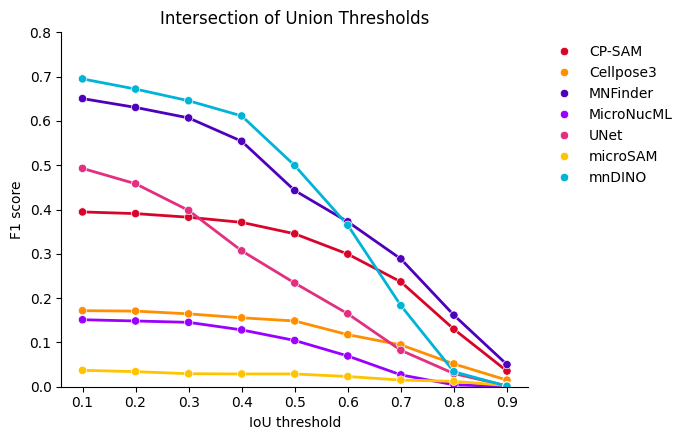

In [83]:
plt.figure(figsize=(7, 4.5))

# Lines only (no markers, no legend of their own)
ax = sns.lineplot(data=df_all, 
                  x='iou_threshold', 
                  y='f1', 
                  hue='methods', 
                  palette=methods_color,
                  linewidth=2, 
                  legend=False)

# Dots whose size follows the F1 score
sns.scatterplot(data=df_all, x='iou_threshold', y='f1', hue='methods', ax=ax, zorder=3, palette=methods_color)

ax.set_xlabel('IoU threshold')
ax.set_ylabel('F1 score')
ax.set_xticks(sorted(df_all['iou_threshold'].unique()))
ax.set_ylim(0, 0.8)
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine()
plt.title('Intersection of Union Thresholds')
plt.tight_layout()
plt.show()

# IoU Scores Averaged by Methods

In [84]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [85]:
folder_path = '/scr/yren/IoUs'
result_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

results = pd.DataFrame()
for file in result_files:
    threshold = file.removeprefix('results_').removesuffix('.csv')
    result = pd.read_csv(os.path.join(folder_path, file))
    # df = result.groupby(['methods'])['f1'].mean().reset_index()
    result['iou_threshold'] = threshold
    results = pd.concat([results, result])

In [86]:
table = results.groupby(['methods', 'datasets', 'iou_threshold'])[['iou_score', 'precision', 'recall', 'f1']].mean().reset_index()
table.head()

,methods,datasets,iou_threshold,iou_score,precision,recall,f1
0,CP-SAM,BBBC039,0.1,0.133507,0.206563,0.345807,0.245235
1,CP-SAM,BBBC039,0.2,0.133507,0.205193,0.344700,0.244012
2,CP-SAM,BBBC039,0.3,0.133507,0.201188,0.336812,0.238730
3,CP-SAM,BBBC039,0.4,0.133507,0.193263,0.327684,0.230358
4,CP-SAM,BBBC039,0.5,0.133507,0.173442,0.280635,0.204323


In [87]:
table

,methods,datasets,iou_threshold,iou_score,precision,recall,f1
0,CP-SAM,BBBC039,0.1,0.133507,0.206563,0.345807,0.245235
1,CP-SAM,BBBC039,0.2,0.133507,0.205193,0.344700,0.244012
2,CP-SAM,BBBC039,0.3,0.133507,0.201188,0.336812,0.238730
3,CP-SAM,BBBC039,0.4,0.133507,0.193263,0.327684,0.230358
4,CP-SAM,BBBC039,0.5,0.133507,0.173442,0.280635,0.204323
...,...,...,...,...,...,...,...
247,mnDINO,mnfinder_test,0.5,0.543512,0.726669,0.632088,0.663744
248,mnDINO,mnfinder_test,0.6,0.543512,0.596406,0.530537,0.552562
249,mnDINO,mnfinder_test,0.7,0.543512,0.314812,0.286137,0.297281
250,mnDINO,mnfinder_test,0.8,0.543512,0.063787,0.059925,0.061525


In [88]:
table.to_csv('/scr/yren/iou_threshold.csv', index=False)

In [89]:
table = pd.read_csv('/scr/yren/iou_threshold.csv')
table = table[table.iou_threshold == 0.1]
table.head()

,methods,datasets,iou_threshold,iou_score,precision,recall,f1
0,CP-SAM,BBBC039,0.1,0.133507,0.206563,0.345807,0.245235
9,CP-SAM,mnDINO_data_01,0.1,0.553167,0.767400,0.632800,0.691933
18,CP-SAM,mnDINO_data_02,0.1,0.427850,0.808750,0.643100,0.716150
27,CP-SAM,mnfinder_test,0.1,0.612981,0.777594,0.657913,0.699925
36,Cellpose3,BBBC039,0.1,0.064428,0.095928,0.201944,0.120237


In [90]:
df = table.groupby(['methods']).mean('iou_score')
df

,iou_threshold,iou_score,precision,recall,f1
methods,,,,,
CP-SAM,0.1,0.431876,0.640077,0.569905,0.588311
Cellpose3,0.1,0.331802,0.503499,0.224817,0.279989
MNFinder,0.1,0.433517,0.654608,0.774406,0.692349
MicroNucML,0.1,0.312845,0.567871,0.253039,0.343061
UNet,0.1,0.244654,0.449959,0.825067,0.562158
microSAM,0.1,0.130059,0.217890,0.032782,0.048699
mnDINO,0.1,0.486976,0.750930,0.824363,0.772795


/tmp/ipykernel_2660035/2853573583.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(df, x='methods', y='iou_score', order=order, palette=methods_color, legend=False)


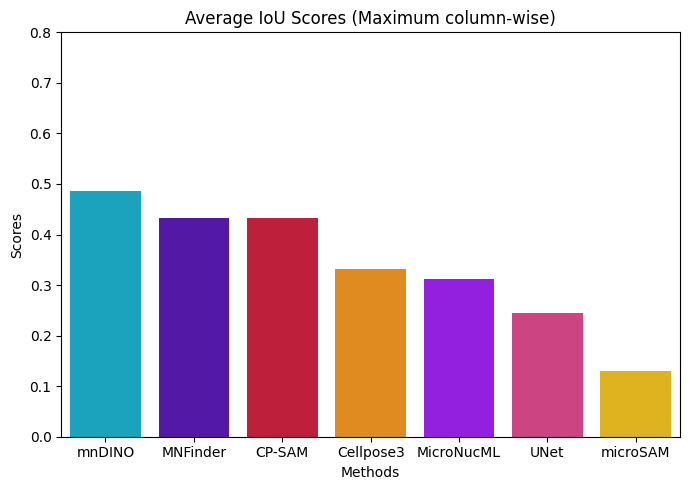

In [91]:
order = df.groupby('methods')['iou_score'].mean().sort_values(ascending=False).index

plt.figure(figsize=(7, 5))
ax = sns.barplot(df, x='methods', y='iou_score', order=order, palette=methods_color, legend=False)
# for container in ax.containers:
#     ax.bar_label(container, fmt='%.3f', padding=3)
ax.set_ylim(0, 0.8)

plt.title('Average IoU Scores (Maximum column-wise)')
plt.xlabel('Methods')
plt.ylabel('Scores')
plt.tight_layout()
plt.show()

## IoU Scores Averaged by Datasets

In [92]:
df_dataset = table.groupby(['methods', 'datasets']).mean('iou_score')

In [93]:
df_dataset

iou_threshold  iou_score  precision    recall  \
methods    datasets                                                        
CP-SAM     BBBC039                   0.1   0.133507   0.206563  0.345807   
           mnDINO_data_01            0.1   0.553167   0.767400  0.632800   
           mnDINO_data_02            0.1   0.427850   0.808750  0.643100   
           mnfinder_test             0.1   0.612981   0.777594  0.657913   
Cellpose3  BBBC039                   0.1   0.064428   0.095928  0.201944   
           mnDINO_data_01            0.1   0.473100   0.662900  0.251200   
           mnDINO_data_02            0.1   0.421200   0.762750  0.269450   
           mnfinder_test             0.1   0.368481   0.492419  0.176675   
MNFinder   BBBC039                   0.1   0.286547   0.510498  0.821616   
           mnDINO_data_01            0.1   0.422767   0.635067  0.727533   
           mnDINO_data_02            0.1   0.412900   0.703500  0.802350   
           mnfinder_test             0.1   0.611856   0.769369  0.746125   
MicroNucML BBBC039                   0.1   0.000000   0.000000  0.000000   
           mnDINO_data_01            0.1   0.433500   0.742967  0.250600   
           mnDINO_data_02            0.1   0.383700   0.765700  0.408100   
           mnfinder_test             0.1   0.434181   0.762819  0.353456   
UNet       BBBC039                   0.1   0.156326   0.338695  0.771388   
           mnDINO_data_01            0.1   0.288367   0.541733  0.863567   
           mnDINO_data_02            0.1   0.266550   0.423800  0.895150   
           mnfinder_test             0.1   0.267375   0.495606  0.770162   
microSAM   BBBC039                   0.1   0.015747   0.027400  0.033851   
           mnDINO_data_01            0.1   0.189633   0.327767  0.043733   
           mnDINO_data_02            0.1   0.089250   0.222200  0.017100   
           mnfinder_test             0.1   0.225606   0.294194  0.036444   
mnDINO     BBBC039                   0.1   0.320493   0.577772  0.791979   
           mnDINO_data_01            0.1   0.520200   0.794767  0.876767   
           mnDINO_data_02            0.1   0.563700   0.795000  0.879800   
           mnfinder_test             0.1   0.543512   0.836181  0.748906   

                                 f1  
methods    datasets                  
CP-SAM     BBBC039         0.245235  
           mnDINO_data_01  0.691933  
           mnDINO_data_02  0.716150  
           mnfinder_test   0.699925  
Cellpose3  BBBC039         0.120237  
           mnDINO_data_01  0.357400  
           mnDINO_data_02  0.395150  
           mnfinder_test   0.247169  
MNFinder   BBBC039         0.611521  
           mnDINO_data_01  0.674700  
           mnDINO_data_02  0.744450  
           mnfinder_test   0.738725  
MicroNucML BBBC039         0.000000  
           mnDINO_data_01  0.373533  
           mnDINO_data_02  0.530150  
           mnfinder_test   0.468562  
UNet       BBBC039         0.451960  
           mnDINO_data_01  0.660267  
           mnDINO_data_02  0.575100  
           mnfinder_test   0.561306  
microSAM   BBBC039         0.025588  
           mnDINO_data_01  0.076533  
           mnDINO_data_02  0.031750  
           mnfinder_test   0.060925  
mnDINO     BBBC039         0.648330  
           mnDINO_data_01  0.833567  
           mnDINO_data_02  0.832400  
           mnfinder_test   0.776881

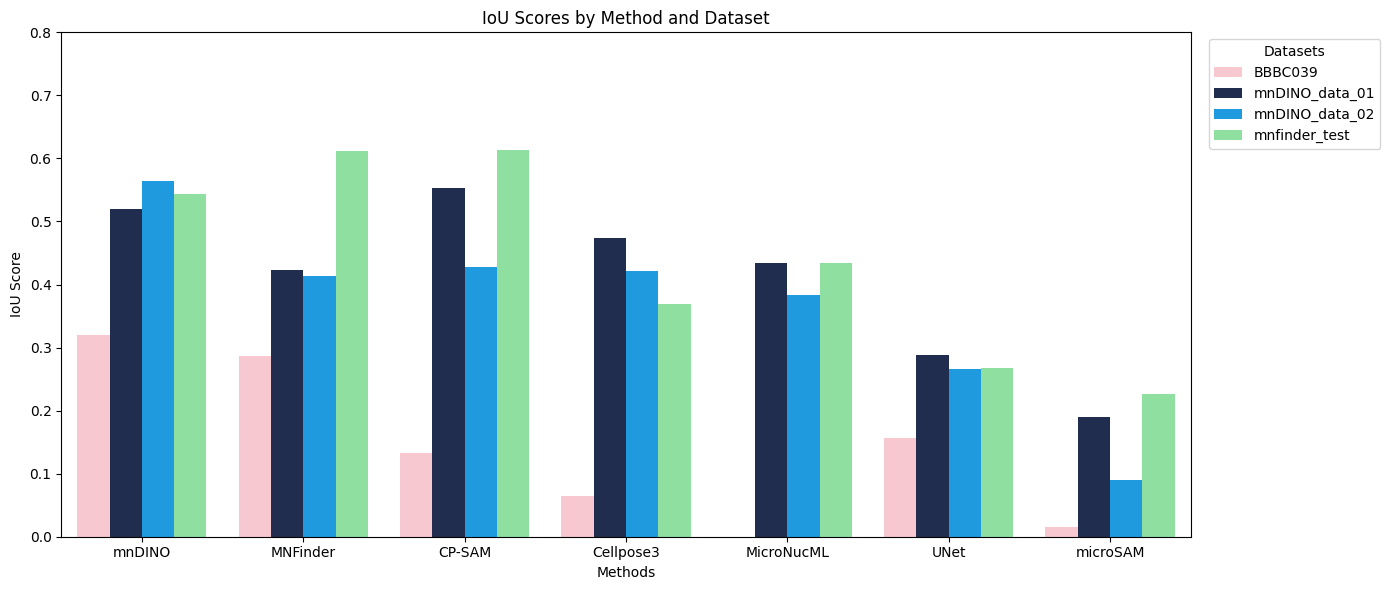

In [94]:
plot_df = df_dataset.reset_index()

# order methods by their mean IoU across datasets (highest first)
order = plot_df.groupby('methods')['iou_score'].mean().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
ax = sns.barplot(plot_df, x='methods', y='iou_score', hue='datasets', palette=datasets_color, order=order)

# for container in ax.containers:
#     ax.bar_label(container, fmt='%.2f', padding=1, fontsize=8, rotation=45)

ax.set_ylim(0, 0.8)
ax.legend(title='Datasets', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.title('IoU Scores by Method and Dataset')
plt.xlabel('Methods')
plt.ylabel('IoU Score')
plt.tight_layout()
plt.show()

In [98]:
df.groupby('methods')['f1'].mean().reset_index()

,methods,f1
0,CP-SAM,0.588311
1,Cellpose3,0.279989
2,MNFinder,0.692349
3,MicroNucML,0.343061
4,UNet,0.562158
5,microSAM,0.048699
6,mnDINO,0.772795


/tmp/ipykernel_2660035/72538045.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(df, x='methods', y='f1', palette=methods_color, order=order)


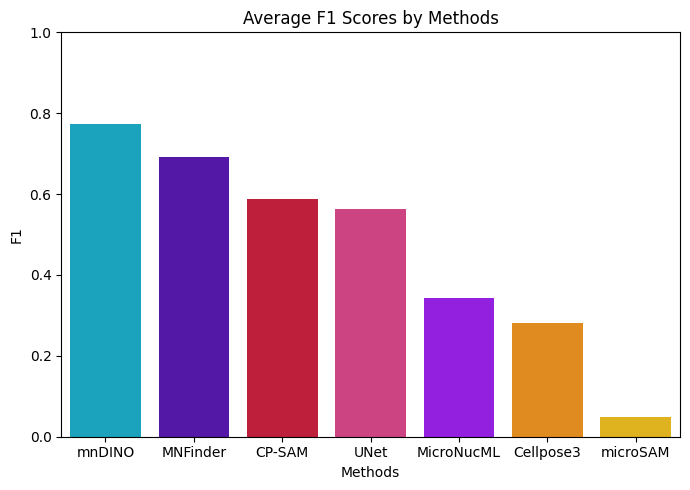

In [96]:
order = df.groupby('methods')['f1'].mean().sort_values(ascending=False).index

plt.figure(figsize=(7, 5))
ax = sns.barplot(df, x='methods', y='f1', palette=methods_color, order=order)
# for container in ax.containers:
#     ax.bar_label(container, fmt='%.3f', padding=3)
ax.set_ylim(0, 1)

plt.title('Average F1 Scores by Methods')
plt.xlabel('Methods')
plt.ylabel('F1')
plt.tight_layout()
plt.show()

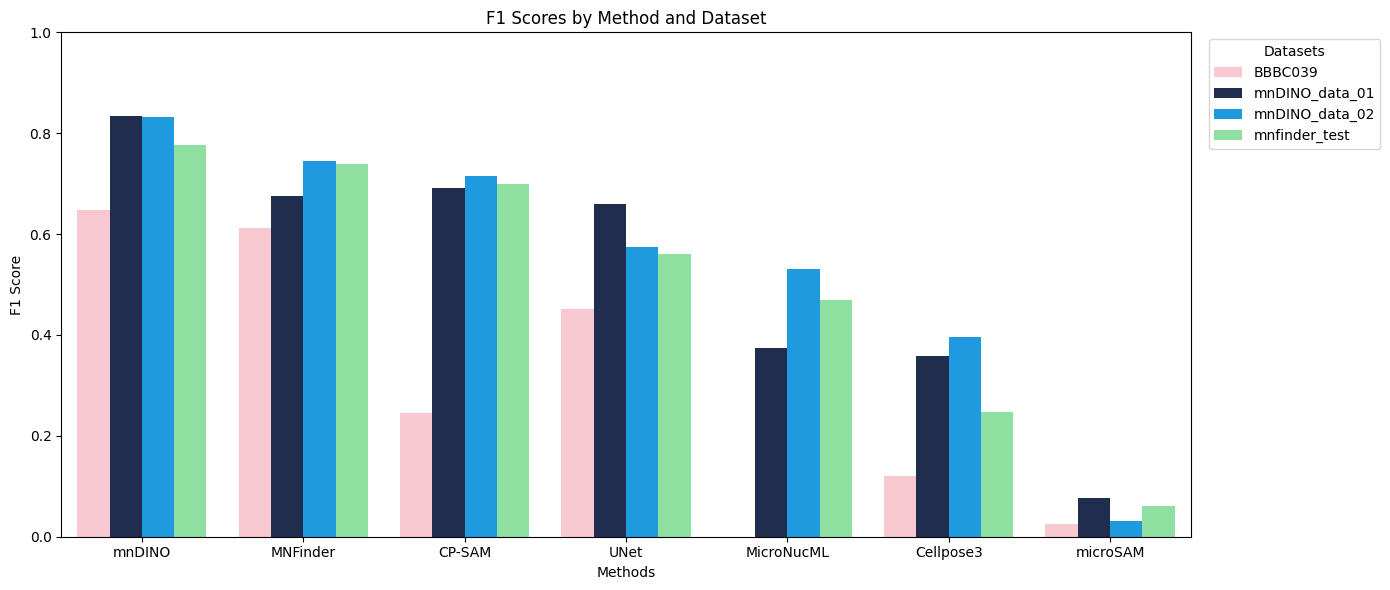

In [97]:
plot_df = df_dataset.reset_index()

# order methods by their mean IoU across datasets (highest first)
order = plot_df.groupby('methods')['f1'].mean().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
ax = sns.barplot(plot_df, x='methods', y='f1', hue='datasets', palette=datasets_color, order=order)

# for container in ax.containers:
#     ax.bar_label(container, fmt='%.2f', padding=1, fontsize=8, rotation=45)

ax.set_ylim(0, 1)
ax.legend(title='Datasets', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.title('F1 Scores by Method and Dataset')
plt.xlabel('Methods')
plt.ylabel('F1 Score')
plt.tight_layout()
plt.show()